# 03. Customer Conversion Funnel & Longitudinal Revenue Concentration Analysis

### Project: E-Commerce Customer Funnel & Cohort Retention Analytics

**Objective:** Aggregate line-item transaction records to the customer grain, construct behavioral conversion funnel stages based on purchase recurrence, evaluate revenue concentration across customer tiers (Pareto distribution), visualize customer distribution via donut and scatter plots, and quantify post-acquisition repurchase latency.


## 1. Environment Configuration & Sanitized Data Ingestion

We ingest the sanitized transaction-level analytical dataset produced by the cleaning pipeline (`retail_cleaned.csv`).


In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

df = pd.read_csv('data/retail_cleaned.csv')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(f'Ingested {len(df):,} sanitized transactions across {df["CustomerID"].nunique():,} unique customers.')
print(f'Observation Window: {df["InvoiceDate"].min().strftime("%Y-%m-%d")} to {df["InvoiceDate"].max().strftime("%Y-%m-%d")}')


Ingested 779,425 sanitized transactions across 5,878 unique customers.
Observation Window: 2009-12-01 to 2011-12-09


## 2. Customer-Grain Behavioral Feature Engineering

Line-item purchases are collapsed into customer-level analytical records to compute lifetime purchase frequency, gross monetary value, and relationship tenure.


In [2]:
# Aggregate behavioral KPIs per customer identifier
customers = df.groupby('CustomerID').agg(
    TotalOrders=('Invoice', 'nunique'),
    TotalSpend=('TotalRevenue', 'sum'),
    TotalItems=('Quantity', 'sum'),
    FirstPurchaseDate=('InvoiceDate', 'min'),
    LastPurchaseDate=('InvoiceDate', 'max')
).reset_index()

# Derive customer tenure and average transaction size
customers['TenureDays'] = (customers['LastPurchaseDate'] - customers['FirstPurchaseDate']).dt.days
customers['AvgOrderValue'] = (customers['TotalSpend'] / customers['TotalOrders']).round(2)
customers['TotalSpend'] = customers['TotalSpend'].round(2)

customers.head(6)


,CustomerID,TotalOrders,TotalSpend,TotalItems,FirstPurchaseDate,LastPurchaseDate,TenureDays,AvgOrderValue
0,12346,12,77556.46,74285,2009-12-14 08:34:00,2011-01-18 10:01:00,400,6463.04
1,12347,8,4921.53,2967,2010-10-31 14:20:00,2011-12-07 15:52:00,402,615.19
2,12348,5,2019.40,2714,2010-09-27 14:59:00,2011-09-25 13:13:00,362,403.88
3,12349,4,4428.69,1624,2010-04-29 13:20:00,2011-11-21 09:51:00,570,1107.17
4,12350,1,334.40,197,2011-02-02 16:01:00,2011-02-02 16:01:00,0,334.40
5,12351,1,300.93,261,2010-11-29 15:23:00,2010-11-29 15:23:00,0,300.93


## 3. Lifecycle Tiering & Conversion Funnel Classification

Customers are segmented into four distinct behavioral stages based on order recurrence:

- **Stage 1 (One-Time Buyer):** 1 completed purchase (high-risk acquisition drop-off).

- **Stage 2 (Repeat Buyer):** Exactly 2 purchases (early activation).

- **Stage 3 (Loyal Buyer):** 3 to 5 purchases (established recurring value).

- **Stage 4 (Champion):** 6+ purchases (core brand advocates and revenue drivers).


In [3]:
def classify_lifecycle_stage(orders):
    if orders == 1:
        return '1. One-Time Buyer'
    elif orders == 2:
        return '2. Repeat Buyer'
    elif orders <= 5:
        return '3. Loyal Buyer (3-5)'
    else:
        return '4. Champion (6+)'

customers['LifecycleStage'] = customers['TotalOrders'].apply(classify_lifecycle_stage)

# Tabulate customer volume per conversion stage
stage_counts = customers['LifecycleStage'].value_counts().sort_index().reset_index()
stage_counts.columns = ['LifecycleStage', 'CustomerCount']
stage_counts['CustomerShare_Pct'] = (stage_counts['CustomerCount'] / stage_counts['CustomerCount'].sum() * 100).round(2)
stage_counts


,LifecycleStage,CustomerCount,CustomerShare_Pct
0,1. One-Time Buyer,1623,27.61
1,2. Repeat Buyer,944,16.06
2,3. Loyal Buyer (3-5),1510,25.69
3,4. Champion (6+),1801,30.64


## 4. Monetary Concentration & Pareto Metrics Calculation

We quantify financial metrics per conversion stage to evaluate revenue generation across tiers.


In [4]:
# Compute financial aggregates per stage
stage_financials = customers.groupby('LifecycleStage')['TotalSpend'].agg(['sum', 'mean']).reset_index()
stage_financials.columns = ['LifecycleStage', 'TotalRevenue', 'AverageCustomerValue']

funnel_summary = stage_counts.merge(stage_financials, on='LifecycleStage')
funnel_summary['RevenueShare_Pct'] = (funnel_summary['TotalRevenue'] / funnel_summary['TotalRevenue'].sum() * 100).round(2)
funnel_summary['TotalRevenue'] = funnel_summary['TotalRevenue'].round(2)
funnel_summary['AverageCustomerValue'] = funnel_summary['AverageCustomerValue'].round(2)

funnel_summary


,LifecycleStage,CustomerCount,CustomerShare_Pct,TotalRevenue,AverageCustomerValue,RevenueShare_Pct
0,1. One-Time Buyer,1623,27.61,560272.56,345.21,3.22
1,2. Repeat Buyer,944,16.06,811434.85,859.57,4.67
2,3. Loyal Buyer (3-5),1510,25.69,2093928.05,1386.71,12.05
3,4. Champion (6+),1801,30.64,13909168.79,7723.03,80.05


## 5. Horizontal Conversion Funnel & Revenue Realization

This dual-panel visual compares customer volume contraction across stages against monetary value progression.


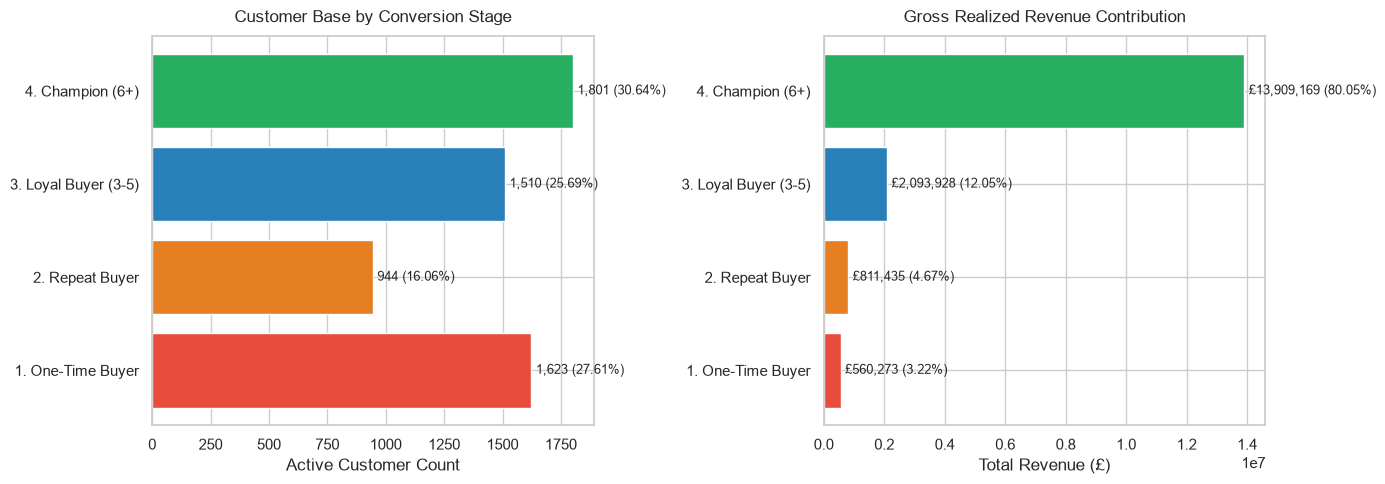

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
palette = ['#e74c3c', '#e67e22', '#2980b9', '#27ae60']

# Customer Volume Funnel
ax1.barh(funnel_summary['LifecycleStage'], funnel_summary['CustomerCount'], color=palette)
ax1.set_title('Customer Base by Conversion Stage', fontsize=12, pad=10)
ax1.set_xlabel('Active Customer Count')
for idx, (count, pct) in enumerate(zip(funnel_summary['CustomerCount'], funnel_summary['CustomerShare_Pct'])):
    ax1.text(count + 20, idx, f'{count:,} ({pct}%)', va='center', fontsize=9)

# Realized Revenue Funnel
ax2.barh(funnel_summary['LifecycleStage'], funnel_summary['TotalRevenue'], color=palette)
ax2.set_title('Gross Realized Revenue Contribution', fontsize=12, pad=10)
ax2.set_xlabel('Total Revenue (£)')
for idx, (rev, pct) in enumerate(zip(funnel_summary['TotalRevenue'], funnel_summary['RevenueShare_Pct'])):
    ax2.text(rev + 150000, idx, f'£{rev:,.0f} ({pct}%)', va='center', fontsize=9)

plt.tight_layout()
plt.show()


## 6. Customer Volume vs. Revenue Share Composition (Donut Visualizations)

Donut charts demonstrate the stark inversion between customer volume share and revenue share.


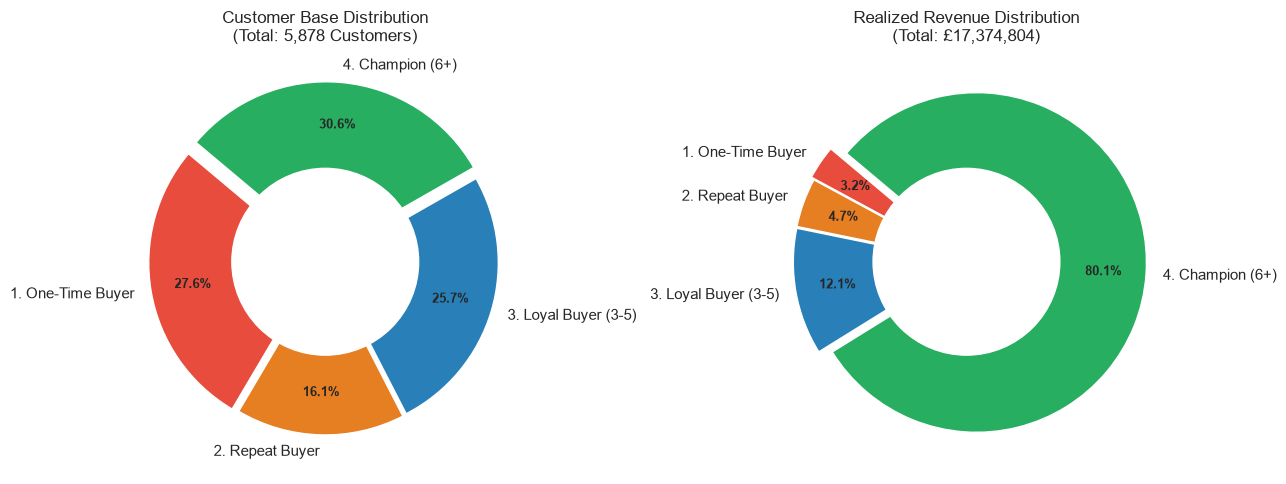

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
explode = (0.04, 0.02, 0.02, 0.06)

# Customer Volume Donut
wedges1, texts1, autotexts1 = ax1.pie(
    funnel_summary['CustomerCount'],
    labels=funnel_summary['LifecycleStage'],
    autopct='%1.1f%%',
    pctdistance=0.75,
    explode=explode,
    colors=palette,
    startangle=140
)
centre_circle1 = plt.Circle((0,0), 0.55, fc='white')
ax1.add_artist(centre_circle1)
ax1.set_title(f'Customer Base Distribution\n(Total: {len(customers):,} Customers)', fontsize=12)

# Revenue Share Donut
wedges2, texts2, autotexts2 = ax2.pie(
    funnel_summary['TotalRevenue'],
    labels=funnel_summary['LifecycleStage'],
    autopct='%1.1f%%',
    pctdistance=0.75,
    explode=explode,
    colors=palette,
    startangle=140
)
centre_circle2 = plt.Circle((0,0), 0.55, fc='white')
ax2.add_artist(centre_circle2)
total_rev_str = f'{funnel_summary["TotalRevenue"].sum():,.0f}'
ax2.set_title(f'Realized Revenue Distribution\n(Total: £{total_rev_str})', fontsize=12)

for at in autotexts1 + autotexts2:
    at.set_fontsize(9)
    at.set_weight('bold')

plt.tight_layout()
plt.show()


## 7. Cumulative Revenue Concentration (Pareto Lorenz Curve)

We sort customers descending by lifetime revenue and compute cumulative shares to empirically validate the 80/20 Pareto principle.


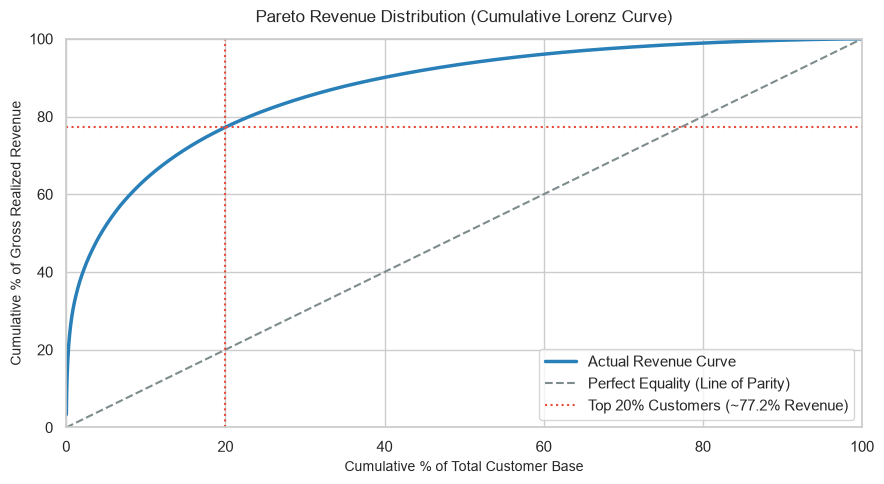

In [7]:
# Sort customers descending by revenue
sorted_customers = customers.sort_values(by='TotalSpend', ascending=False).reset_index(drop=True)
sorted_customers['CumCustomerPct'] = (sorted_customers.index + 1) / len(sorted_customers) * 100
sorted_customers['CumRevenuePct'] = (sorted_customers['TotalSpend'].cumsum() / sorted_customers['TotalSpend'].sum()) * 100

top20_pct_rev = sorted_customers.iloc[int(len(sorted_customers) * 0.20)]['CumRevenuePct']

plt.figure(figsize=(9, 5))
plt.plot(sorted_customers['CumCustomerPct'], sorted_customers['CumRevenuePct'], color='#2980b9', lw=2.5, label='Actual Revenue Curve')
plt.plot([0, 100], [0, 100], color='#7f8c8d', linestyle='--', label='Line of Equality')

# 80/20 reference markers
plt.axvline(x=20, color='#e74c3c', linestyle=':', lw=1.5, label=f'Top 20% Customers (~{top20_pct_rev:.1f}% Revenue)')
plt.axhline(y=top20_pct_rev, color='#e74c3c', linestyle=':', lw=1.5)

plt.title('Pareto Revenue Distribution (Cumulative Lorenz Curve)', fontsize=12, pad=12)
plt.xlabel('Cumulative % of Total Customer Base', fontsize=10)
plt.ylabel('Cumulative % of Gross Realized Revenue', fontsize=10)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()


## 8. Customer Spend vs. Order Frequency (Dotted / Scatter Distribution)

A multi-variable scatter plot maps transaction frequency (`TotalOrders`) against log-scaled monetary spend (`TotalSpend`), with dot sizes scaled by Average Order Value (`AvgOrderValue`).


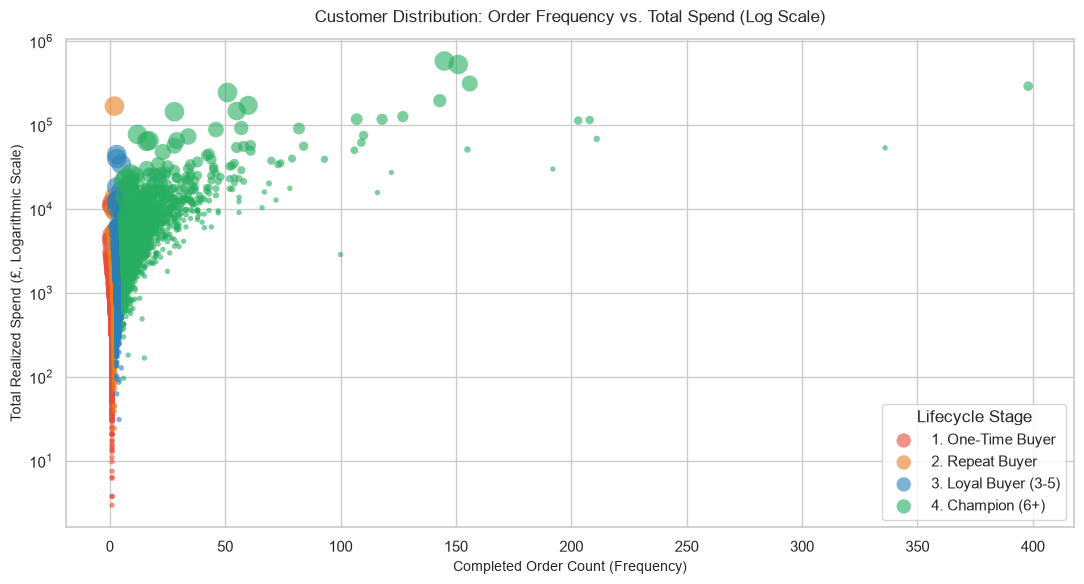

In [8]:
plt.figure(figsize=(11, 6))

stage_color_map = {
    '1. One-Time Buyer': '#e74c3c',
    '2. Repeat Buyer': '#e67e22',
    '3. Loyal Buyer (3-5)': '#2980b9',
    '4. Champion (6+)': '#27ae60'
}

# Plot each lifecycle stage with scaled dot size
for stage, group in customers.groupby('LifecycleStage'):
    sizes = np.clip(group['AvgOrderValue'] / 15, 15, 200)
    plt.scatter(
        group['TotalOrders'],
        group['TotalSpend'],
        label=stage,
        color=stage_color_map[stage],
        s=sizes,
        alpha=0.6,
        edgecolors='none'
    )

plt.yscale('log')
plt.title('Customer Distribution: Order Frequency vs. Total Spend (Log Scale)', fontsize=12, pad=12)
plt.xlabel('Completed Order Count (Frequency)', fontsize=10)
plt.ylabel('Total Realized Spend (£, Logarithmic Scale)', fontsize=10)
plt.legend(title='Lifecycle Stage', frameon=True, loc='lower right')
plt.tight_layout()
plt.show()


## 9. Average Order Value (AOV) Spread by Lifecycle Stage (Boxplot)

We evaluate how basket value scales across conversion tiers, highlighting median order sizes and outlier dispersion.


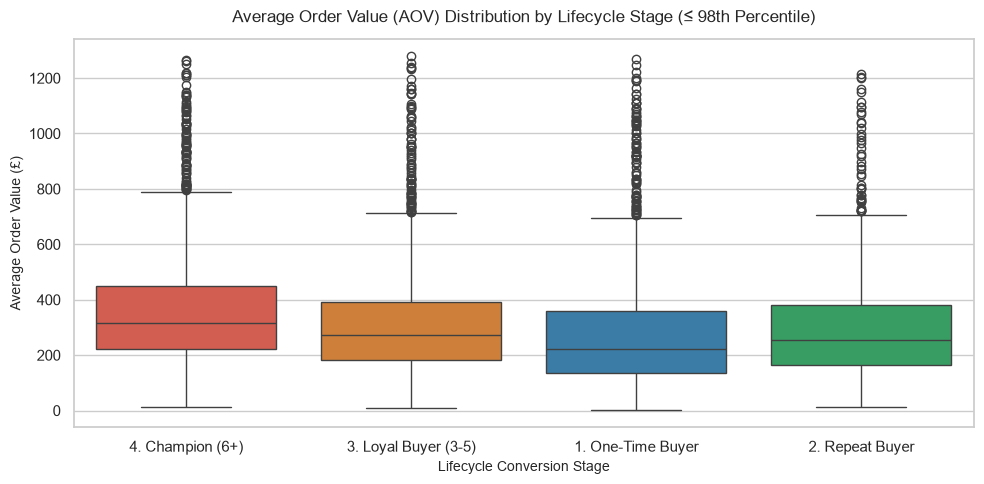

In [9]:
# Filter upper 2% outliers to preserve visual resolution
p98 = customers['AvgOrderValue'].quantile(0.98)
filtered_customers = customers[customers['AvgOrderValue'] <= p98]

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=filtered_customers,
    x='LifecycleStage',
    y='AvgOrderValue',
    palette=['#e74c3c', '#e67e22', '#2980b9', '#27ae60']
)

plt.title('Average Order Value (AOV) Distribution by Lifecycle Stage (≤ 98th Percentile)', fontsize=12, pad=12)
plt.xlabel('Lifecycle Conversion Stage', fontsize=10)
plt.ylabel('Average Order Value (£)', fontsize=10)
plt.tight_layout()
plt.show()


## 10. Repurchase Latency & The 30-Day Activation Window

To identify optimal reactivation timing, we compute the elapsed days between first and second transaction for repeat purchasers.


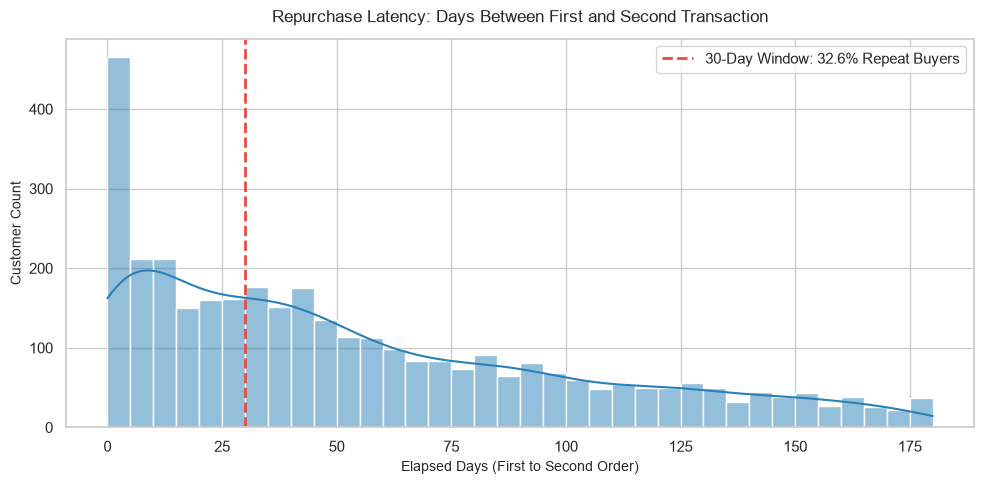

In [10]:
# Filter repeat buyers to calculate repurchase latency
repeat_cust_ids = customers[customers['TotalOrders'] >= 2]['CustomerID']
df_repeat = df[df['CustomerID'].isin(repeat_cust_ids)]

orders_sorted = df_repeat.groupby(['CustomerID', 'Invoice'])['InvoiceDate'].min().reset_index().sort_values(['CustomerID', 'InvoiceDate'])
orders_sorted['OrderRank'] = orders_sorted.groupby('CustomerID').cumcount() + 1

order1 = orders_sorted[orders_sorted['OrderRank'] == 1].set_index('CustomerID')['InvoiceDate']
order2 = orders_sorted[orders_sorted['OrderRank'] == 2].set_index('CustomerID')['InvoiceDate']

latency_days = (order2 - order1).dt.days.dropna()
under_30 = (latency_days <= 30).sum() / len(latency_days) * 100

plt.figure(figsize=(10, 5))
sns.histplot(latency_days[latency_days <= 180], bins=36, kde=True, color='#2980b9', edgecolor='white')
plt.axvline(x=30, color='#e74c3c', linestyle='--', lw=2, label=f'30-Day Window: {under_30:.1f}% Repeat Buyers')

plt.title('Repurchase Latency: Days Between First and Second Transaction', fontsize=12, pad=12)
plt.xlabel('Elapsed Days (First to Second Order)', fontsize=10)
plt.ylabel('Customer Count', fontsize=10)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 11. Strategic Findings & Analytical Serialization

We serialize customer-grain behavioral summaries and funnel aggregations to feed relational database ingestion and Power BI semantic models.


In [11]:
one_time_share = funnel_summary.loc[funnel_summary['LifecycleStage'] == '1. One-Time Buyer', 'CustomerShare_Pct'].values[0]
champ_rev_share = funnel_summary.loc[funnel_summary['LifecycleStage'] == '4. Champion (6+)', 'RevenueShare_Pct'].values[0]
champ_cust_share = funnel_summary.loc[funnel_summary['LifecycleStage'] == '4. Champion (6+)', 'CustomerShare_Pct'].values[0]

print('=== Strategic Analytical Conclusions ===')
print(f'1. Acquisition Drop-Off: {one_time_share}% of all customers churn after exactly one transaction.')
print(f'2. Revenue Concentration: Champions represent {champ_cust_share}% of customers but generate {champ_rev_share}% of total revenue.')
print(f'3. Re-engagement Window: {under_30:.1f}% of repeat purchases occur within 30 days of acquisition.\n')

# Export analytical datasets
customers.to_csv('data/customer_summary.csv', index=False)
funnel_summary.to_csv('data/funnel_summary.csv', index=False)
print('Saved data/customer_summary.csv and data/funnel_summary.csv successfully.')


=== Strategic Analytical Conclusions ===
1. Acquisition Drop-Off: 27.61% of all customers churn after exactly one transaction.
2. Revenue Concentration: Champions represent 30.64% of customers but generate 80.05% of total revenue.
3. Re-engagement Window: 32.6% of repeat purchases occur within 30 days of acquisition.

Saved data/customer_summary.csv and data/funnel_summary.csv successfully.
